# Amazon Top 50 Bestselling Books (2009–2019)

An exploratory data analysis of the 550 books that made Amazon's yearly Top 50 list between 2009 and 2019.

**Questions I wanted to answer**
1. How much of the list is really *new* books, and how much is the same books coming back year after year?
2. Which authors dominate the list?
3. Did prices change over the decade?
4. Do fiction and non-fiction behave differently (rating, reviews, price)?
5. Are rating, reviews, price and year related to each other?

**Data:** [Amazon Top 50 Bestselling Books 2009–2019](https://www.kaggle.com/sootersaalu/amazon-top-50-bestselling-books-2009-2019) on Kaggle (550 rows, 7 columns).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Two colours for the two genres, used everywhere in this notebook
FIC, NON = '#2a6fbb', '#d9822b'
GENRE_COLORS = {'Fiction': FIC, 'Non Fiction': NON}

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': .25, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titleweight': 'bold', 'axes.titlesize': 12,
})

df = pd.read_csv('data/bestsellers.csv')
df.columns = ['name', 'author', 'rating', 'reviews', 'price', 'year', 'genre']
df.head()

,name,author,rating,reviews,price,year,genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


## 1. Data check and cleaning

In [2]:
print(df.shape)
print(df.isna().sum().to_string())
print('Exact duplicate rows:', df.duplicated().sum())
print('Books per year:', df.year.value_counts().unique())
print('Distinct titles:', df.name.nunique(), '| distinct authors:', df.author.nunique())
print('Rows with Price = 0:', (df.price == 0).sum())

(550, 7)
name       0
author     0
rating     0
reviews    0
price      0
year       0
genre      0
Exact duplicate rows: 0
Books per year: [50]
Distinct titles: 351 | distinct authors: 248
Rows with Price = 0: 12


**What I found**
- No missing values and no exact duplicate rows. Every year has exactly 50 books (11 years × 50 = 550).
- But there are only **351 distinct titles**: the same book can appear in several years, so rows are *book-year* observations, not unique books. I count unique titles whenever the question is about "books", and rows when it is about "list spots".
- **12 rows have Price = 0**. These are almost certainly free or unavailable listings (e.g. *To Kill a Mockingbird* in 2013–2016), not real prices, so I exclude them from price analysis only.
- Two author names are cut off in the source (e.g. "Delegates of the Constitutional"). I left them as they are; they do not affect the results.

In [3]:
df['price_clean'] = df.price.where(df.price > 0)   # 0 -> missing, for price analysis only
titles = df.drop_duplicates('name')                 # one row per distinct title
print(len(titles), 'distinct titles')

351 distinct titles


## 2. How much of the list is repeat books?

Titles that appear in only 1 year : 255
Titles that appear in 5+ years    : 17


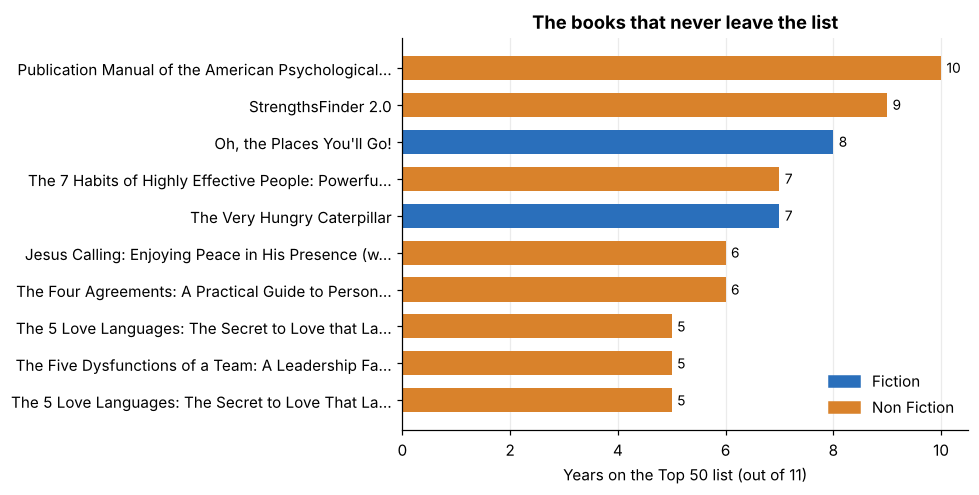

In [4]:
years_on_list = (df.groupby(['name', 'author', 'genre']).year.nunique()
                   .rename('years_on_list').reset_index()
                   .sort_values('years_on_list', ascending=False))

print('Titles that appear in only 1 year :', (years_on_list.years_on_list == 1).sum())
print('Titles that appear in 5+ years    :', (years_on_list.years_on_list >= 5).sum())

top = years_on_list.head(10).iloc[::-1]
labels = top.name.str.slice(0, 48) + np.where(top.name.str.len() > 48, '…', '')
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(labels, top.years_on_list, color=[GENRE_COLORS[g] for g in top.genre], height=.65)
ax.set_xlabel('Years on the Top 50 list (out of 11)')
ax.set_title('The books that never leave the list')
for i, v in enumerate(top.years_on_list):
    ax.text(v + .1, i, str(v), va='center', fontsize=9)
ax.grid(axis='y', visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GENRE_COLORS.values()]
ax.legend(handles, GENRE_COLORS.keys(), frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig('images/01_years_on_list.png'); plt.show()

**Takeaway:** the list is much more stable than "550 bestsellers" suggests. About 7 in 10 titles (255 of 351) appear in a single year, but a small core of evergreen books keeps coming back. Reference and self-help titles lead (the APA *Publication Manual* is on the list 10 of 11 years, *StrengthsFinder 2.0* 9 times), alongside children's classics such as *Oh, the Places You'll Go!*. (Two of the bars near the bottom are the same book, *The 5 Love Languages*, under slightly different title spellings.)

## 3. Which authors dominate?

Authors with a single list spot: 130 of 248


,list_spots,distinct_titles
author,,
Jeff Kinney,12,12
Rick Riordan,11,10
Suzanne Collins,11,5
Gary Chapman,11,3
American Psychological Association,10,1
Dr. Seuss,9,2
Gallup,9,1
Rob Elliott,8,2
Stephenie Meyer,7,7


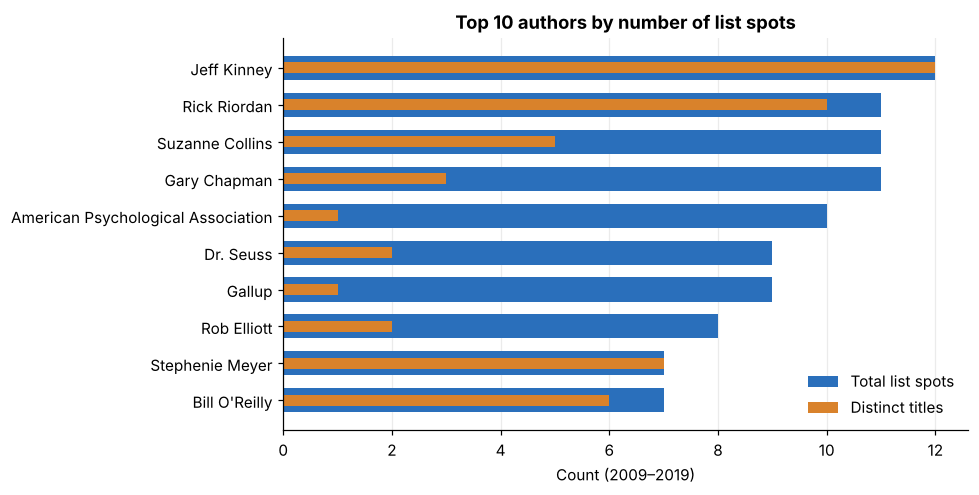

In [5]:
authors = (df.groupby('author')
             .agg(list_spots=('name', 'size'), distinct_titles=('name', 'nunique'))
             .sort_values(['list_spots', 'distinct_titles'], ascending=False))

print('Authors with a single list spot:', (authors.list_spots == 1).sum(), 'of', len(authors))
display(authors.head(10))

top = authors.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(top.index, top.list_spots, color='#2a6fbb', height=.65, label='Total list spots')
ax.barh(top.index, top.distinct_titles, color='#d9822b', height=.3, label='Distinct titles')
ax.set_xlabel('Count (2009–2019)')
ax.set_title('Top 10 authors by number of list spots')
ax.grid(axis='y', visible=False)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig('images/02_top_authors.png'); plt.show()

**Takeaway:** the list is long-tailed. Out of 248 authors, 130 (just over half) appear once. At the top, **Jeff Kinney** has the most list spots (12) and it is 12 *different* Diary of a Wimpy Kid books. Others get their spots differently: **Gary Chapman** has 11 spots but is essentially one book, *The 5 Love Languages*, listed under 3 slightly different titles, and the **APA** has 10 spots from a single manual. So "most spots" means two different things: a prolific series versus one evergreen book.

## 4. Did prices change?

year,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
median,12.0,13.00,13.00,13.0,13.00,11.00,9.00,9.50,9.00,8.00,10.00
mean,15.4,13.76,15.41,15.3,15.21,15.91,10.63,13.73,11.61,10.52,10.08


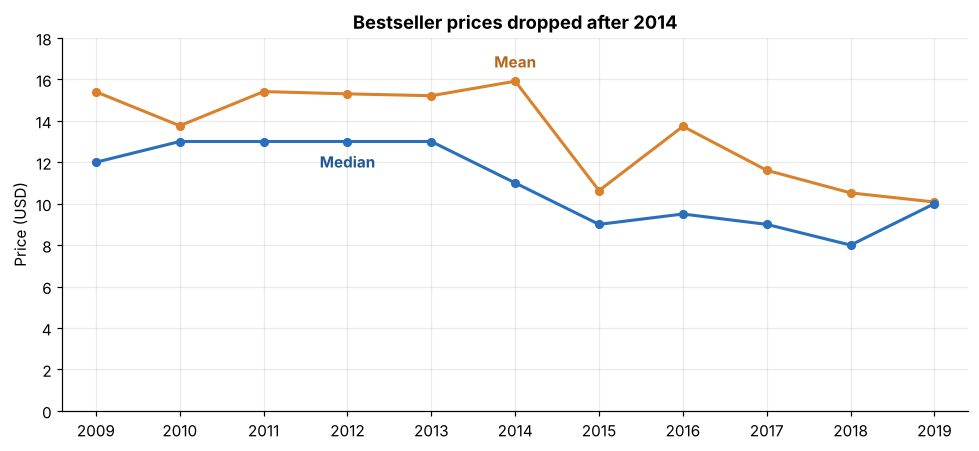

Share of priced list spots at $10 or less: 47.2 %


In [6]:
price_year = df.groupby('year').price_clean.agg(['median', 'mean']).round(2)
display(price_year.T)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(price_year.index, price_year['mean'], color='#d9822b', lw=2, marker='o', ms=5)
ax.plot(price_year.index, price_year['median'], color='#2a6fbb', lw=2, marker='o', ms=5)
ax.annotate('Mean', (2014, price_year['mean'].loc[2014]), xytext=(0, 9), textcoords='offset points', color='#b3661a', ha='center', fontweight='bold')
ax.annotate('Median', (2012, price_year['median'].loc[2012]), xytext=(0, -17), textcoords='offset points', color='#1f5896', ha='center', fontweight='bold')
ax.set_xlim(2008.6, 2019.4); ax.set_ylim(0, 18)
ax.set_xticks(range(2009, 2020))
ax.set_ylabel('Price (USD)')
ax.set_title('Bestseller prices dropped after 2014')
plt.tight_layout(); plt.savefig('images/03_price_by_year.png'); plt.show()

print('Share of priced list spots at $10 or less:', round((df.price_clean <= 10).sum() / df.price_clean.notna().sum() * 100, 1), '%')

**Takeaway:** the typical bestseller got cheaper. The median price sat around $13 in 2010–2013 and was $8–$10 from 2015 on. The mean dropped from $15.91 in 2014 to $10.63 in 2015. I show the median alongside the mean because a handful of expensive items (the $105 DSM-5, the $82 *Twilight* box set) pull the mean up. Close to half of all priced list spots (47%) cost $10 or less.

*Caveat:* this shows prices fell *among bestsellers*. It does not prove why (cheaper formats, different mix of books, or pricing changes); the data cannot separate these.

## 5. Fiction vs non-fiction

,list_spots,mean_rating,lowest_rating,median_reviews,median_price
genre,,,,,
Fiction,240,4.65,3.3,10922.0,9.0
Non Fiction,310,4.60,4.0,6346.0,12.0


Books rated below 4.0 -> Fiction: 7 | Non Fiction: 0


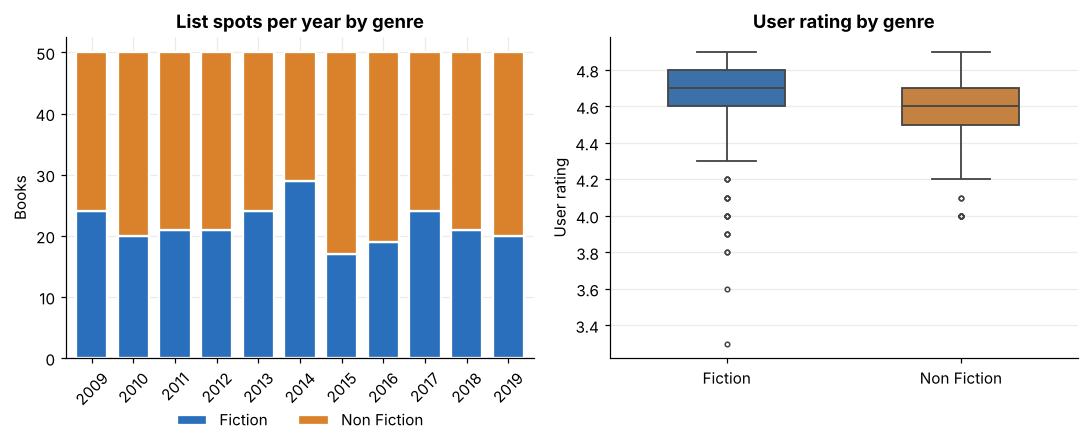

In [7]:
genre_counts = pd.crosstab(df.year, df.genre)
summary = df.groupby('genre').agg(
    list_spots=('name', 'size'),
    mean_rating=('rating', 'mean'),
    lowest_rating=('rating', 'min'),
    median_reviews=('reviews', 'median'),
    median_price=('price_clean', 'median')).round(2)
display(summary)
print('Books rated below 4.0 -> Fiction:', ((df.genre == 'Fiction') & (df.rating < 4)).sum(),
      '| Non Fiction:', ((df.genre == 'Non Fiction') & (df.rating < 4)).sum())

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
genre_counts.plot(kind='bar', stacked=True, ax=axes[0], color=[FIC, NON], width=.75, edgecolor='white', linewidth=1.5)
axes[0].set_title('List spots per year by genre'); axes[0].set_xlabel(''); axes[0].set_ylabel('Books')
axes[0].legend(frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(.5, -.12))
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df, x='genre', y='rating', hue='genre', order=['Fiction', 'Non Fiction'], hue_order=['Fiction', 'Non Fiction'], palette=GENRE_COLORS, ax=axes[1],
            width=.5, linewidth=1.2, fliersize=3, legend=False)
axes[1].set_title('User rating by genre'); axes[1].set_xlabel(''); axes[1].set_ylabel('User rating')
plt.tight_layout(); plt.savefig('images/04_fiction_vs_nonfiction.png'); plt.show()

**Takeaway:** non-fiction holds more spots (310 vs 240) but the two genres are close on ratings (mean 4.60 vs 4.65). The difference is in the extremes and in reader activity:
- **Every list spot rated below 4.0 is fiction** (7 spots, from 5 different titles), including the lowest, *The Casual Vacancy* (3.3). No non-fiction title dropped below 4.0.
- Fiction gets noticeably more reviews (median 10,922 vs 6,346) while non-fiction is more expensive (median $12 vs $9).

## 6. Are the numbers related?

         rating  reviews  price  year
rating     1.00     0.20  -0.21  0.29
reviews    0.20     1.00  -0.17  0.39
price     -0.21    -0.17   1.00 -0.22
year       0.29     0.39  -0.22  1.00


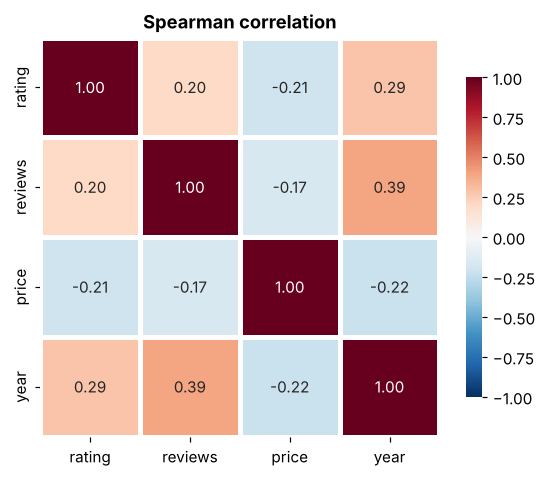

In [8]:
corr = df[['rating', 'reviews', 'price_clean', 'year']].rename(columns={'price_clean': 'price'}).corr(method='spearman')
print(corr.round(2))

fig, ax = plt.subplots(figsize=(5.4, 4.4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=2, linecolor='white', cbar_kws={'shrink': .8}, ax=ax)
ax.set_title("Spearman correlation"); ax.grid(False)
plt.tight_layout(); plt.savefig('images/05_correlation.png'); plt.show()

**Takeaway:** all relationships are weak (|ρ| ≤ 0.39). I used Spearman rather than Pearson because reviews and price are heavily skewed.
- Rating is slightly higher for cheaper books (ρ = −0.21) and for later years (ρ = 0.29).
- Reviews rise with year (ρ = 0.39), but treat this with care: the review count is a **snapshot** taken when the data was collected (the same book shows the identical count in every year it appears), so newer books simply have had less time to differ. It does not mean readers reviewed more over time.
- Rating and number of reviews are only weakly linked (ρ = 0.20): a highly rated book is not necessarily a heavily reviewed one.

## 7. Summary

| Question | Answer |
|---|---|
| How many *different* books? | 351 distinct titles behind 550 list spots; 255 appear in only one year, 17 in five or more |
| Who dominates? | Long tail: 130 of 248 authors appear once. Jeff Kinney leads with 12 spots (12 different titles) |
| Did prices change? | Median fell from ~$13 (2010–13) to $8–10 (2015–19) |
| Fiction vs non-fiction | Non-fiction has more spots; fiction gets more reviews; all 7 list spots rated under 4.0 are fiction |
| Any strong relationships? | No. All correlations are weak (|ρ| ≤ 0.39) |

**Limitations**
- Only the Top 50 per year, so this says nothing about books outside the list.
- Reviews are a single snapshot, not a time series.
- Genre is only Fiction / Non Fiction, which is too coarse to say which *topics* sell.
- Titles are matched by exact text, so editions and spelling variants of the same book count as separate titles (351 is therefore a slight overcount of truly distinct books).
- Price = 0 rows were excluded from price analysis.

**Ideas for next steps:** label the topic of each title (self-help, children, thriller…) and compare; check whether a book's price change from one year to the next relates to its rank.